# Base-case economic strategy evaluation

This notebook is the inspection layer for the canonical strategy runner. It first compares EWMA, GARCH, HAR, the two GBM specifications, and trailing volatility with buy-and-hold under the fixed daily volatility-targeting configuration, then repeats the economic evaluation with weekly and monthly decision schedules. Forecasts remain daily and one step ahead in every case except the two-day horizon section, which sizes on forecasts of the return day. The runner computes every return, metric, and test; the notebook presents the resulting tables, volatility control, turnover, and gross and net cumulative earnings.

Run it from the `notebooks/` directory after the dataset and all forecast caches have been built. The runner writes its tables, return series, and provenance to `data/cache/`, outside version control.

In [1]:
from dataclasses import replace

import sys

import matplotlib.pyplot as plt
import pandas as pd

sys.path.insert(0, "..")

from backtest.targeting import WEEKDAYS, BacktestConfig
from evaluation.capacity import average_dollar_volume, capacity_table, spy_dollar_volume
from evaluation.run_forecasts import TRAIN_END
from evaluation.run_strategies import BENCHMARK, frictions, run, strategy_run_dir
from evaluation.strategy import evaluate_strategy, rolling_volatility, sharpe_difference_test

## Canonical tables

All strategies use a 10% annual volatility target, a 1.5x leverage cap, a 5 percentage-point no-trade band, execution at the close after the decision (the weight decided at the close of t earns the return of t+2), 2 bps one-way transaction costs, and a 50 bps annual funding spread above the risk-free rate. Buy-and-hold pays only its initial transaction cost.

This notebook focuses on H2 and H3. H2 asks whether the strategy using the best forecast keeps realized volatility closer to target and improves Sharpe relative to unmanaged SPY and the same strategy using other models. H3 asks whether those improvements survive transaction costs, execution lag, turnover, and the real-time information constraint. H1, forecast accuracy, is evaluated separately.

The gross table describes H2 before transaction costs; the net table describes H3 after costs. Both include Sharpe, drawdown, turnover, target tracking, vol-of-vol, and tail metrics. The spanning tables regress each strategy's excess return on the buy-and-hold benchmark's excess return and report the Newey-West test of alpha. The runner refuses to combine forecasts with a different frozen snapshot.

### H2 objective: gross economic performance

Compare the models before transaction costs. Evidence for H2 requires the best forecast to improve volatility control and downside behavior without sacrificing gross risk-adjusted performance relative to the other models and buy-and-hold. This table is descriptive; the spanning and paired Sharpe tables below provide the formal return tests.

In [2]:
base_config = BacktestConfig()
tables = run(config=base_config)
tables["gross_metrics"].round(4)

,sharpe,maximum_drawdown,annualized_turnover,realized_volatility,target_volatility_gap,vol_of_vol,worst_return_1,worst_return_2,worst_return_3,worst_return_4,worst_return_5,skew,kurtosis
strategy,,,,,,,,,,,,,
ewma,0.7463,-0.1544,4.1974,0.1059,0.0059,0.0332,-0.0485,-0.0470,-0.0417,-0.0362,-0.0343,-0.8475,3.8171
garch,0.7583,-0.1406,6.7884,0.0997,-0.0003,0.0266,-0.0407,-0.0391,-0.0377,-0.0334,-0.0331,-0.8173,3.2217
har,0.7906,-0.1493,15.2114,0.0990,-0.0010,0.0245,-0.0356,-0.0343,-0.0327,-0.0317,-0.0301,-0.6971,2.2582
gbm,0.7793,-0.1550,23.4294,0.1008,0.0008,0.0235,-0.0377,-0.0358,-0.0334,-0.0317,-0.0307,-0.6944,2.2047
gbm_vix,0.7791,-0.1470,23.0799,0.0993,-0.0007,0.0230,-0.0374,-0.0306,-0.0303,-0.0295,-0.0284,-0.6597,1.8616
trailing,0.7421,-0.1600,3.8116,0.1089,0.0089,0.0346,-0.0460,-0.0379,-0.0362,-0.0351,-0.0346,-0.7721,3.1169
buy_and_hold,0.7732,-0.3372,0.0608,0.1716,0.0716,0.1022,-0.1094,-0.0957,-0.0781,-0.0651,-0.0585,-0.3312,12.0077


### H3 objective: implementable net performance

Evaluate the same strategies after transaction costs. H3 is supported only if the economic improvement seen gross remains after daily execution, the no-trade band, turnover, funding costs, and the execution lag already enforced by the backtester.

In [3]:
tables["net_metrics"].round(4)

,sharpe,maximum_drawdown,annualized_turnover,realized_volatility,target_volatility_gap,vol_of_vol,worst_return_1,worst_return_2,worst_return_3,worst_return_4,worst_return_5,skew,kurtosis
strategy,,,,,,,,,,,,,
ewma,0.7384,-0.1547,4.2019,0.1060,0.0060,0.0332,-0.0485,-0.0470,-0.0417,-0.0362,-0.0343,-0.8478,3.8173
garch,0.7444,-0.1409,6.7782,0.0997,-0.0003,0.0266,-0.0407,-0.0391,-0.0377,-0.0334,-0.0331,-0.8177,3.2228
har,0.7598,-0.1502,15.2115,0.0990,-0.0010,0.0245,-0.0356,-0.0343,-0.0327,-0.0318,-0.0301,-0.6970,2.2587
gbm,0.7324,-0.1569,23.4422,0.1008,0.0008,0.0235,-0.0377,-0.0358,-0.0335,-0.0317,-0.0307,-0.6945,2.2059
gbm_vix,0.7325,-0.1488,23.0805,0.0993,-0.0007,0.0230,-0.0374,-0.0307,-0.0303,-0.0295,-0.0285,-0.6596,1.8608
trailing,0.7351,-0.1604,3.8116,0.1089,0.0089,0.0346,-0.0460,-0.0379,-0.0362,-0.0351,-0.0346,-0.7725,3.1173
buy_and_hold,0.7732,-0.3372,0.0608,0.1716,0.0716,0.1022,-0.1094,-0.0957,-0.0781,-0.0651,-0.0585,-0.3312,12.0078


### H2 objective: gross alpha beyond passive SPY exposure

Test whether each strategy adds gross return beyond its exposure to buy-and-hold SPY. The relevant output is the Newey-West alpha statistic and its two-sided p-value; beta shows how much passive market exposure remains.

In [4]:
tables["h2_spanning"].round(4)

,alpha_daily,alpha_annual,beta,alpha_stat,alpha_pvalue,newey_west_lag
strategy,,,,,,
ewma,0.0,0.0073,0.5404,0.5503,0.5821,14.0
garch,0.0,0.0084,0.5061,0.6662,0.5053,18.0
har,0.0,0.0114,0.5038,0.9055,0.3652,20.0
gbm,0.0,0.0111,0.5085,0.8335,0.4046,21.0
gbm_vix,0.0,0.0108,0.5018,0.8180,0.4133,22.0
trailing,0.0,0.0069,0.5563,0.5232,0.6008,13.0


### H3 objective: net alpha after implementation costs

Repeat the spanning test on net returns. The objective is to determine whether any gross alpha remains after transaction costs while the passive benchmark pays only its initial cost.

In [5]:
tables["h3_spanning"].round(4)

,alpha_daily,alpha_annual,beta,alpha_stat,alpha_pvalue,newey_west_lag
strategy,,,,,,
ewma,0.0,0.0065,0.5404,0.4874,0.6259,14.0
garch,0.0,0.0070,0.5061,0.5564,0.5779,18.0
har,0.0,0.0083,0.5038,0.6638,0.5068,20.0
gbm,0.0,0.0064,0.5086,0.4794,0.6317,21.0
gbm_vix,0.0,0.0062,0.5018,0.4683,0.6395,22.0
trailing,0.0,0.0062,0.5563,0.4659,0.6413,13.0


## Pairwise Sharpe tests against the passive benchmark

The complete cached tables contain Ledoit-Wolf comparisons for every strategy pair. The views below isolate each model against buy-and-hold. A Sharpe difference is reported as model minus passive, with a two-sided bootstrap p-value.

### H2 objective: gross Sharpe improvement

Test whether each volatility-managed strategy has a higher gross Sharpe than unmanaged SPY. The paired bootstrap accounts for both strategies being driven by the same daily market returns.

In [6]:
h2_against_passive = tables["h2_sharpe"].reset_index()
h2_against_passive.loc[h2_against_passive["strategy_b"] == BENCHMARK].round(4)

,strategy_a,strategy_b,sharpe_difference,statistic,pvalue,block_size,bootstrap_reps
5,ewma,buy_and_hold,-0.0270,-0.2211,0.8012,75.0,1000.0
10,garch,buy_and_hold,-0.0149,-0.1250,0.8851,75.0,1000.0
14,har,buy_and_hold,0.0173,0.1446,0.8841,75.0,1000.0
17,gbm,buy_and_hold,0.0061,0.0490,0.9630,75.0,1000.0
19,gbm_vix,buy_and_hold,0.0059,0.0473,0.9510,75.0,1000.0
20,trailing,buy_and_hold,-0.0312,-0.2619,0.7802,75.0,1000.0


### H3 objective: net Sharpe improvement

Repeat the paired comparison after transaction costs. H3 requires a gross Sharpe advantage to remain economically and statistically distinguishable from buy-and-hold in net returns.

In [7]:
h3_against_passive = tables["h3_sharpe"].reset_index()
h3_against_passive.loc[h3_against_passive["strategy_b"] == BENCHMARK].round(4)

,strategy_a,strategy_b,sharpe_difference,statistic,pvalue,block_size,bootstrap_reps
5,ewma,buy_and_hold,-0.0348,-0.2852,0.7512,75.0,1000.0
10,garch,buy_and_hold,-0.0287,-0.2424,0.7942,75.0,1000.0
14,har,buy_and_hold,-0.0134,-0.1121,0.9131,75.0,1000.0
17,gbm,buy_and_hold,-0.0407,-0.3292,0.7413,75.0,1000.0
19,gbm_vix,buy_and_hold,-0.0407,-0.3288,0.7233,75.0,1000.0
20,trailing,buy_and_hold,-0.0381,-0.3202,0.7303,75.0,1000.0


## Exposure, trading, and cost drag

Objective: explain why gross results do or do not survive into H3. Average and maximum held weights describe market exposure; the leverage share counts days above one; trade frequency and average trade size show how often and how far the strategy rebalances; annualized cost drag is the difference between mean gross and net return.

In [8]:
diagnostics = tables["strategy_diagnostics"]
diagnostics.round(4)

,average_held_weight,maximum_held_weight,leverage_days_share,cap_days_share,trade_days_per_year,average_trade_size,annualized_cost_drag
strategy,,,,,,,
ewma,0.7863,1.5,0.2009,0.0304,52.6368,0.0798,0.0008
garch,0.7527,1.5,0.1821,0.0053,77.6787,0.0873,0.0014
har,0.7728,1.5,0.2130,0.0176,129.6469,0.1173,0.0030
gbm,0.8024,1.5,0.2564,0.0263,161.2533,0.1454,0.0047
gbm_vix,0.8028,1.5,0.2600,0.0285,160.2200,0.1441,0.0046
trailing,0.8113,1.5,0.2619,0.0294,45.7077,0.0834,0.0008
buy_and_hold,1.0000,1.0,0.0000,0.0000,0.0608,1.0000,0.0000


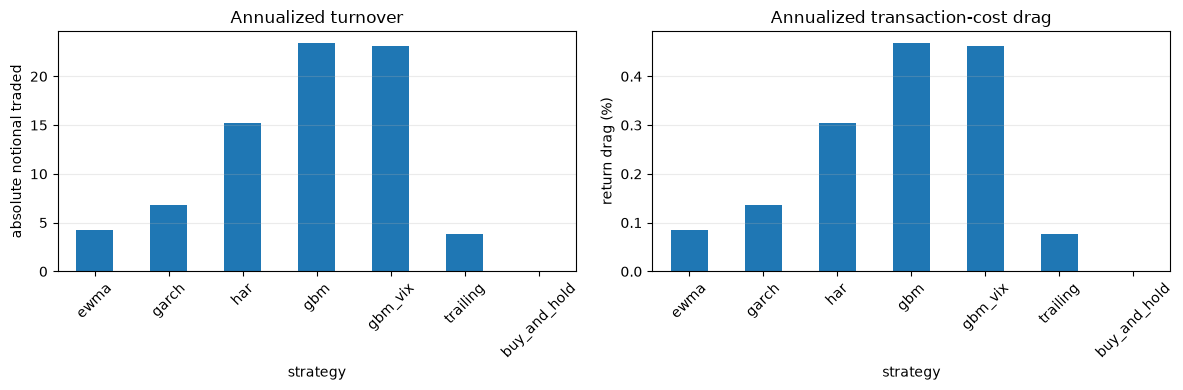

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
tables["net_metrics"]["annualized_turnover"].plot.bar(ax=axes[0])
(diagnostics["annualized_cost_drag"] * 100).plot.bar(ax=axes[1])
axes[0].set_title("Annualized turnover")
axes[0].set_ylabel("absolute notional traded")
axes[1].set_title("Annualized transaction-cost drag")
axes[1].set_ylabel("return drag (%)")
for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

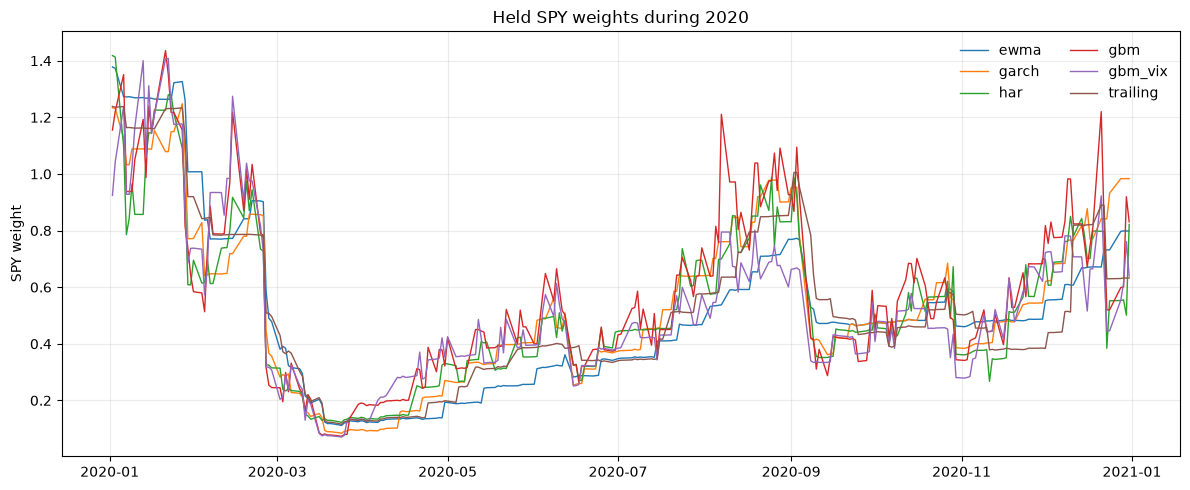

In [10]:
returns = pd.read_parquet(strategy_run_dir(TRAIN_END, base_config) / "returns.parquet")
held_weights = returns.xs("held_weight", axis=1, level=1)
fig, ax = plt.subplots(figsize=(12, 5))
for name in held_weights.columns.drop(BENCHMARK):
    ax.plot(held_weights.loc["2020"].index, held_weights.loc["2020", name], lw=1.0, label=name)
ax.set_title("Held SPY weights during 2020")
ax.set_ylabel("SPY weight")
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Capacity against SPY volume

Objective: size the capital the strategies could run before their own trades become a visible share of SPY volume. On every trade day, the trailing 21-day average dollar volume of SPY ending on the trade day (the ledger row holds the trade made at the previous close), times a 1% participation share, over the turnover of the day gives the capital whose trade would take that share. The table reports the median, the 5th percentile and the minimum of that capital in billions of dollars over trade days after the initial position, and the share of volume that one billion dollars of capital would take on the median and worst trade day, in basis points. Participation at 1% of volume is a convention for a trade that is unlikely to move the price, not a measured impact.

In [11]:
turnover = returns.xs("turnover", axis=1, level=1).drop(columns=BENCHMARK)
capacity = capacity_table(turnover, average_dollar_volume(spy_dollar_volume()))
capacity[["capacity_median", "capacity_p05", "capacity_min"]] /= 1e9
capacity[["reference_share_median", "reference_share_max"]] *= 1e4
capacity.round(3)

,trade_days_per_year,median_trade_size,capacity_median,capacity_p05,capacity_min,reference_share_median,reference_share_max
strategy,,,,,,,
ewma,52.589,0.063,3.448,1.341,0.293,29.005,341.176
garch,77.637,0.069,3.357,1.153,0.274,29.789,364.671
har,129.617,0.096,2.572,0.822,0.336,38.887,297.182
gbm,161.231,0.117,2.152,0.624,0.304,46.477,328.626
gbm_vix,160.198,0.118,2.136,0.612,0.297,46.814,337.190
trailing,45.658,0.068,3.376,1.232,0.462,29.617,216.297


## Gross and net cumulative performance

The charts compound the exact gross and net return series cached by the runner. Their separation shows the accumulated effect of transaction costs. They are visual alignment and plausibility checks, not substitutes for the paired tests above: ending wealth alone does not establish economic significance.

In [12]:
gross_returns = returns.xs("gross_return", axis=1, level=1)
net_returns = returns.xs("net_return", axis=1, level=1)
assert not gross_returns.isna().any().any()
assert not net_returns.isna().any().any()
gross_wealth = (1.0 + gross_returns).cumprod()
net_wealth = (1.0 + net_returns).cumprod()

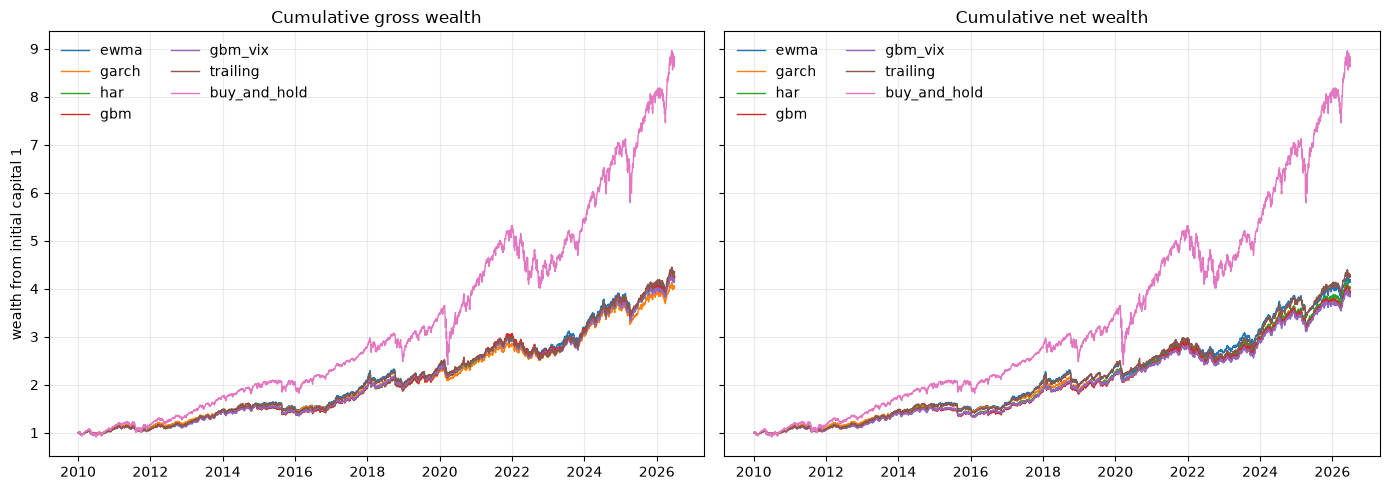

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for name in gross_wealth:
    axes[0].plot(gross_wealth.index, gross_wealth[name], lw=1.0, label=name)
    axes[1].plot(net_wealth.index, net_wealth[name], lw=1.0, label=name)
axes[0].set_title("Cumulative gross wealth")
axes[1].set_title("Cumulative net wealth")
axes[0].set_ylabel("wealth from initial capital 1")
for ax in axes:
    ax.legend(frameon=False, ncol=2)
    ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Volatility control

Objective: evaluate the risk-control component of H2 directly. Realized volatility summarizes the full sample, the target gap measures average bias from 10%, and vol-of-vol is the Hong-style root mean squared deviation of rolling 21-day annualized volatility from that target. The time-series chart shows when control succeeds or breaks down, including the passive portfolio as a reference.

In [14]:
volatility_summary = tables["net_metrics"][[
    "realized_volatility", "target_volatility_gap", "vol_of_vol"
]].sort_values("vol_of_vol")
volatility_summary.round(4)

,realized_volatility,target_volatility_gap,vol_of_vol
strategy,,,
gbm_vix,0.0993,-0.0007,0.0230
gbm,0.1008,0.0008,0.0235
har,0.0990,-0.0010,0.0245
garch,0.0997,-0.0003,0.0266
ewma,0.1060,0.0060,0.0332
trailing,0.1089,0.0089,0.0346
buy_and_hold,0.1716,0.0716,0.1022


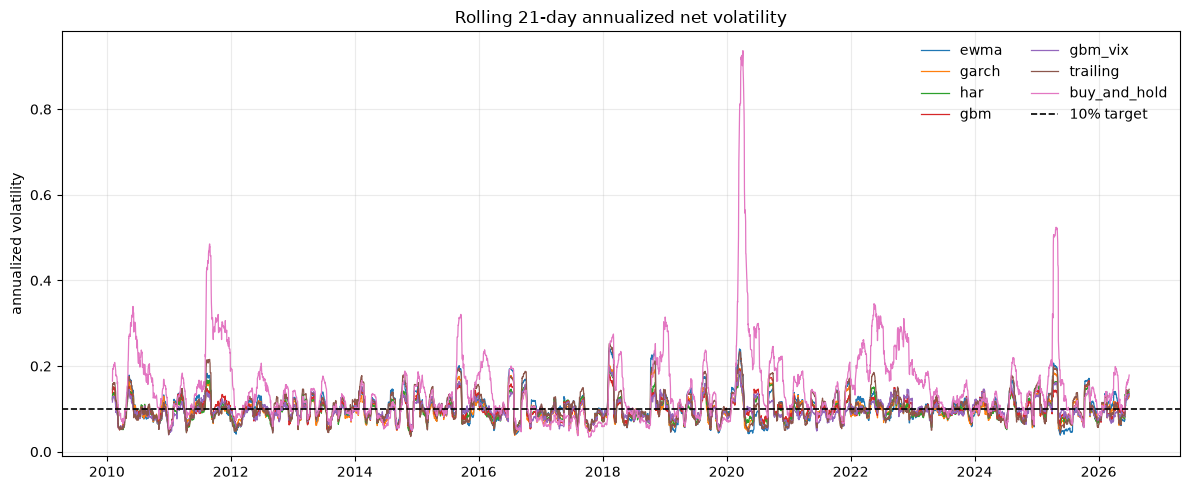

In [15]:
rolling_net_volatility = pd.DataFrame({
    name: rolling_volatility(net_returns[name]) for name in net_returns
})
fig, ax = plt.subplots(figsize=(12, 5))
for name in rolling_net_volatility:
    ax.plot(rolling_net_volatility.index, rolling_net_volatility[name], lw=0.9, label=name)
ax.axhline(0.10, color="black", ls="--", lw=1.2, label="10% target")
ax.set_title("Rolling 21-day annualized net volatility")
ax.set_ylabel("annualized volatility")
ax.legend(frameon=False, ncol=2)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()

## Sub-period robustness

Objective: check whether the base-case ranking depends on one stretch of the sample. The cached net returns are cut into the first half (2010 to 2017), the second half (2018 to 2026) and the full sample without 2020, the year of the largest volatility spike. Each cut is evaluated with the same metric function and the same paired Ledoit-Wolf test against buy-and-hold, with the bootstrap seed of the base case. The halves are contiguous. The ex-2020 cut joins December 2019 to January 2021, so the 21-day windows behind vol-of-vol, the drawdown and the bootstrap blocks of the Sharpe test run across that joint as if the days were consecutive.

In [16]:
sub_periods = {
    "2010-2017": slice("2010", "2017"),
    "2018-2026": slice("2018", "2026"),
    "ex-2020": returns.index.year != 2020,
}
net_turnover = returns.xs("turnover", axis=1, level=1)
rf_series = returns.xs("rf", axis=1, level=1)
sub_period_rows = {}
for label, cut in sub_periods.items():
    cut_returns = net_returns.loc[cut]
    for name in cut_returns:
        metrics = evaluate_strategy(
            cut_returns[name],
            rf_series.loc[cut, name],
            net_turnover.loc[cut, name],
            base_config.target_vol_annual,
        )[["sharpe", "maximum_drawdown", "annualized_turnover", "realized_volatility", "vol_of_vol"]]
        if name != BENCHMARK:
            metrics["pvalue_vs_passive"] = sharpe_difference_test(
                cut_returns[name], cut_returns[BENCHMARK], rf_series.loc[cut, name]
            )["pvalue"]
        sub_period_rows[(label, name)] = metrics
sub_period_summary = pd.DataFrame.from_dict(sub_period_rows, orient="index")
sub_period_summary.index = sub_period_summary.index.set_names(["period", "strategy"])
sub_period_summary.round(4)

sharpe  maximum_drawdown  annualized_turnover  \
period    strategy                                                      
2010-2017 ewma          0.9077           -0.1231               4.6203   
          garch         0.8968           -0.1152               6.0838   
          har           0.8444           -0.1390              13.9845   
          gbm           0.8149           -0.1416              23.3642   
          gbm_vix       0.8384           -0.1408              23.7628   
          trailing      0.8681           -0.1293               3.6762   
          buy_and_hold  0.9313           -0.1861               0.1252   
2018-2026 ewma          0.5850           -0.1547               3.8074   
          garch         0.6101           -0.1409               7.4329   
          har           0.6837           -0.1502              16.3683   
          gbm           0.6595           -0.1569              23.5158   
          gbm_vix       0.6378           -0.1488              22.4373   
          trailing      0.6147           -0.1604               3.9393   
          buy_and_hold  0.6713           -0.3372               0.0000   
ex-2020   ewma          0.7568           -0.1547               4.2692   
          garch         0.7416           -0.1409               6.8186   
          har           0.7543           -0.1502              15.4095   
          gbm           0.7235           -0.1569              23.7118   
          gbm_vix       0.7248           -0.1488              23.5816   
          trailing      0.7505           -0.1604               3.8067   
          buy_and_hold  0.8177           -0.2450               0.0647   

                        realized_volatility  vol_of_vol  pvalue_vs_passive  
period    strategy                                                          
2010-2017 ewma                       0.1037      0.0296             0.8761  
          garch                      0.0963      0.0255             0.8052  
          har                        0.0966      0.0244             0.5415  
          gbm                        0.0978      0.0238             0.4176  
          gbm_vix                    0.0967      0.0225             0.5305  
          trailing                   0.1066      0.0320             0.6494  
          buy_and_hold               0.1465      0.0753                NaN  
2018-2026 ewma                       0.1080      0.0363             0.5854  
          garch                      0.1027      0.0277             0.7043  
          har                        0.1012      0.0247             0.9351  
          gbm                        0.1037      0.0233             0.9371  
          gbm_vix                    0.1018      0.0236             0.8472  
          trailing                   0.1110      0.0369             0.6873  
          buy_and_hold               0.1923      0.1225                NaN  
ex-2020   ewma                       0.1054      0.0317             0.5295  
          garch                      0.0989      0.0257             0.3776  
          har                        0.0984      0.0239             0.4396  
          gbm                        0.0998      0.0224             0.2717  
          gbm_vix                    0.0990      0.0222             0.2557  
          trailing                   0.1083      0.0332             0.3996  
          buy_and_hold               0.1550      0.0806                NaN

## Friction attribution

Objective: locate where the gross edge goes, one friction at a time. The first three rows carry no cap, band or costs and differ only in execution timing: lag 0 applies the weight decided with the close of t to the return of t itself, a deliberate look-ahead that is reported only as a diagnostic; lag 1 is the same-close order the literature assumes and that would need the close before it is known; lag 2 is the implementable case and the base of everything else. The two_day row keeps lag 2 and sizes on the cached two-day forecast of the return day, so the distance from lag 2 to two_day is what a forecast built for that day wins back of the distance from lag 1 to lag 2. The next rows add the leverage cap, the no-trade band and the transaction costs on top of the lag-2 case, so the last row equals the net base-case table above. The runner writes both tables next to the base-case tables of the same configuration.

In [17]:
friction_tables = frictions(config=base_config)
attribution = friction_tables["friction_attribution"]
layers = attribution.index.unique("layer")
attribution["sharpe"].unstack("strategy").reindex(layers).round(3)

strategy,ewma,garch,gbm,gbm_vix,har,trailing
layer,,,,,,
lag_0,1.072,1.315,2.588,2.771,1.325,0.979
lag_1,0.782,0.806,0.824,0.825,0.850,0.811
lag_2,0.749,0.771,0.773,0.784,0.796,0.762
two_day,0.749,0.775,0.798,0.804,0.799,0.762
cap,0.752,0.772,0.772,0.778,0.794,0.756
band,0.746,0.758,0.779,0.779,0.791,0.742
costs,0.738,0.744,0.732,0.732,0.760,0.735


In [18]:
attribution[["annualized_turnover", "maximum_drawdown", "vol_of_vol"]].round(4)

annualized_turnover  maximum_drawdown  vol_of_vol
layer   strategy                                                   
lag_0   ewma                   6.6945           -0.1147      0.0223
        garch                  9.2833           -0.0943      0.0203
        har                   18.4647           -0.1135      0.0210
        gbm                   26.8210           -0.0615      0.0167
        gbm_vix               26.5468           -0.0558      0.0173
        trailing               5.4906           -0.1486      0.0263
lag_1   ewma                   6.7317           -0.1487      0.0297
        garch                  9.3029           -0.1284      0.0231
        har                   18.4961           -0.1471      0.0220
        gbm                   26.6154           -0.1555      0.0210
        gbm_vix               26.3048           -0.1455      0.0210
        trailing               5.5294           -0.1593      0.0307
lag_2   ewma                   6.7212           -0.1634      0.0332
        garch                  9.3160           -0.1418      0.0264
        har                   18.5517           -0.1567      0.0243
        gbm                   26.7937           -0.1560      0.0232
        gbm_vix               26.5210           -0.1503      0.0227
        trailing               5.5342           -0.1616      0.0335
two_day ewma                   6.7212           -0.1634      0.0332
        garch                  9.0115           -0.1401      0.0263
        har                   20.9804           -0.1534      0.0241
        gbm                   21.0821           -0.1519      0.0235
        gbm_vix               20.5695           -0.1452      0.0233
        trailing               5.5342           -0.1616      0.0335
cap     ewma                   6.2843           -0.1572      0.0329
        garch                  9.2689           -0.1418      0.0264
        har                   17.8687           -0.1567      0.0244
        gbm                   25.5526           -0.1560      0.0233
        gbm_vix               25.2030           -0.1503      0.0228
        trailing               5.2426           -0.1616      0.0335
band    ewma                   4.1974           -0.1544      0.0332
        garch                  6.7884           -0.1406      0.0266
        har                   15.2114           -0.1493      0.0245
        gbm                   23.4294           -0.1550      0.0235
        gbm_vix               23.0799           -0.1470      0.0230
        trailing               3.8116           -0.1600      0.0346
costs   ewma                   4.2019           -0.1547      0.0332
        garch                  6.7782           -0.1409      0.0266
        har                   15.2115           -0.1502      0.0245
        gbm                   23.4422           -0.1569      0.0235
        gbm_vix               23.0805           -0.1488      0.0230
        trailing               3.8116           -0.1604      0.0346

### No-trade band sensitivity

The base case with the band at 0, 2.5, 5 and 10 percentage points, everything else unchanged. A band of zero trades to the target every day.

In [19]:
band = friction_tables["band_sensitivity"]
band[["sharpe", "annualized_turnover", "maximum_drawdown", "vol_of_vol"]].round(4)

sharpe  annualized_turnover  maximum_drawdown  vol_of_vol
layer      strategy                                                           
band_0.000 ewma      0.7403               6.2839           -0.1575      0.0329
           garch     0.7531               9.2685           -0.1423      0.0264
           har       0.7574              17.8687           -0.1581      0.0244
           gbm       0.7215              25.5533           -0.1583      0.0233
           gbm_vix   0.7270              25.2037           -0.1526      0.0228
           trailing  0.7467               5.2426           -0.1622      0.0335
band_0.025 ewma      0.7426               5.2475           -0.1555      0.0329
           garch     0.7585               8.4202           -0.1419      0.0264
           har       0.7526              17.0194           -0.1608      0.0245
           gbm       0.7216              24.9458           -0.1563      0.0233
           gbm_vix   0.7249              24.6028           -0.1535      0.0229
           trailing  0.7457               4.3914           -0.1593      0.0338
band_0.050 ewma      0.7384               4.2019           -0.1547      0.0332
           garch     0.7444               6.7782           -0.1409      0.0266
           har       0.7598              15.2115           -0.1502      0.0245
           gbm       0.7324              23.4422           -0.1569      0.0235
           gbm_vix   0.7325              23.0805           -0.1488      0.0230
           trailing  0.7351               3.8116           -0.1604      0.0346
band_0.100 ewma      0.7260               3.2030           -0.1614      0.0347
           garch     0.7534               4.9064           -0.1359      0.0277
           har       0.7620              11.5031           -0.1451      0.0253
           gbm       0.7412              19.5543           -0.1437      0.0240
           gbm_vix   0.7047              19.4380           -0.1561      0.0234
           trailing  0.7214               3.1662           -0.1586      0.0361

### Volatility target sensitivity

Raising the target to 15% and 20% scales every weight up while leaving the cap, band, costs and execution lag unchanged, so it shows what the same forecasts are worth when the strategy runs with more leverage. Buy-and-hold does not depend on the target, but its vol-of-vol is measured against each target, so that column is only comparable within a row group. `cap_days_share` is the share of days whose raw weight reaches the 1.5x cap; `leverage_days_share` counts days held above 1. The paired Ledoit-Wolf columns are the net p-values of each model against the GBM and against buy-and-hold.

In [20]:
targets = (0.10, 0.15, 0.20)
target_tables = {
    target: tables if target == base_config.target_vol_annual
    else run(config=replace(base_config, target_vol_annual=target))
    for target in targets
}


def paired_pvalues(sharpe_table, against):
    pairs = sharpe_table.reset_index()
    forward = pairs.loc[pairs["strategy_b"] == against].set_index("strategy_a")
    backward = pairs.loc[pairs["strategy_a"] == against].set_index("strategy_b")
    return pd.concat([forward, backward])["pvalue"]


target_summary = pd.concat(
    {
        target: result["net_metrics"][[
            "sharpe", "maximum_drawdown", "annualized_turnover",
            "realized_volatility", "vol_of_vol",
        ]].join(result["strategy_diagnostics"][[
            "average_held_weight", "leverage_days_share", "cap_days_share",
        ]]).assign(
            pvalue_vs_gbm=paired_pvalues(result["h3_sharpe"], "gbm"),
            pvalue_vs_passive=paired_pvalues(result["h3_sharpe"], BENCHMARK),
        )
        for target, result in target_tables.items()
    },
    names=["target"],
)
target_summary.round(4)

sharpe  maximum_drawdown  annualized_turnover  \
target strategy                                                      
0.10   ewma          0.7384           -0.1547               4.2019   
       garch         0.7444           -0.1409               6.7782   
       har           0.7598           -0.1502              15.2115   
       gbm           0.7324           -0.1569              23.4422   
       gbm_vix       0.7325           -0.1488              23.0805   
       trailing      0.7351           -0.1604               3.8116   
       buy_and_hold  0.7732           -0.3372               0.0608   
0.15   ewma          0.7490           -0.1974               4.9308   
       garch         0.7734           -0.1851               8.9042   
       har           0.7620           -0.2322              17.0050   
       gbm           0.7498           -0.2303              22.7399   
       gbm_vix       0.7395           -0.2261              22.6507   
       trailing      0.7453           -0.2359               3.9899   
       buy_and_hold  0.7732           -0.3372               0.0608   
0.20   ewma          0.8108           -0.2496               3.0503   
       garch         0.8293           -0.2490               6.4077   
       har           0.7790           -0.3038              11.6143   
       gbm           0.7617           -0.2955              14.9668   
       gbm_vix       0.7675           -0.2962              14.6251   
       trailing      0.7580           -0.3115               2.9193   
       buy_and_hold  0.7732           -0.3372               0.0608   

                     realized_volatility  vol_of_vol  average_held_weight  \
target strategy                                                             
0.10   ewma                       0.1060      0.0332               0.7863   
       garch                      0.0997      0.0266               0.7527   
       har                        0.0990      0.0245               0.7728   
       gbm                        0.1008      0.0235               0.8024   
       gbm_vix                    0.0993      0.0230               0.8028   
       trailing                   0.1089      0.0346               0.8113   
       buy_and_hold               0.1716      0.1022               1.0000   
0.15   ewma                       0.1517      0.0472               1.1099   
       garch                      0.1454      0.0400               1.0888   
       har                        0.1433      0.0386               1.0938   
       gbm                        0.1454      0.0368               1.1264   
       gbm_vix                    0.1435      0.0369               1.1245   
       trailing                   0.1546      0.0493               1.1265   
       buy_and_hold               0.1716      0.0909               1.0000   
0.20   ewma                       0.1818      0.0662               1.2915   
       garch                      0.1760      0.0606               1.2775   
       har                        0.1753      0.0604               1.2788   
       gbm                        0.1758      0.0588               1.2922   
       gbm_vix                    0.1751      0.0591               1.2946   
       trailing                   0.1835      0.0679               1.2904   
       buy_and_hold               0.1716      0.1052               1.0000   

                     leverage_days_share  cap_days_share  pvalue_vs_gbm  \
target strategy                                                           
0.10   ewma                       0.2009          0.0304         0.9321   
       garch                      0.1821          0.0053         0.8232   
       har                        0.2130          0.0176         0.3866   
       gbm                        0.2564          0.0263            NaN   
       gbm_vix                    0.2600          0.0285         0.9990   
       trailing                   0.2619          0.0294         0.9570   
       buy_and_hold               0.00

At 10% the cap binds on 0.5 to 3% of days and the average weight is near 0.8, so the headline rule already lets the weight follow the forecast almost everywhere. At 15% the cap binds on 19 to 27% of the days, at 20% on 50 to 55%, with average weights near 1.1 and 1.3. The spread between models widens with the target, 0.73 to 0.76 at 10% against 0.76 to 0.83 at 20%, and the order at 20% is the reverse of QLIKE: GARCH and EWMA, which trade a fraction of the GBM's turnover, come out ahead, while the two GBM sit at the bottom. No model beats buy-and-hold at any target, all those p-values are above 0.5, and against the GBM the smallest p-value is GARCH at 20%, 0.07. Across all 21 pairs at 20% one comparison is below 0.05, GARCH against trailing at 0.04, which is what multiplicity alone would produce. Drawdowns grow with leverage from about 15% to about 30%.

### Sizing rule sensitivity

Two ways of letting the weight follow the forecast where the headline rule does not. The first keeps target over forecast volatility and moves the leverage cap: 1.5x (base), 2x, 3x and no cap, with band and costs unchanged, from the same friction runner as the band table. The second keeps the 1.5x cap and squares the rule, weight equal to target variance over forecast variance, the scaling of Moreira and Muir without their in-sample calibration constant: it agrees with the headline rule when the forecast sits at the target and moves twice as far in log terms away from it. The uncapped and squared cases are full runs, so their paired Ledoit-Wolf p-values are available.

In [21]:
cap = friction_tables["cap_sensitivity"]
cap[["sharpe", "maximum_drawdown", "annualized_turnover", "realized_volatility", "vol_of_vol"]].round(4)

sharpe  maximum_drawdown  annualized_turnover  \
layer    strategy                                                  
cap_1.5  ewma      0.7384           -0.1547               4.2019   
         garch     0.7444           -0.1409               6.7782   
         har       0.7598           -0.1502              15.2115   
         gbm       0.7324           -0.1569              23.4422   
         gbm_vix   0.7325           -0.1488              23.0805   
         trailing  0.7351           -0.1604               3.8116   
cap_2.0  ewma      0.7347           -0.1612               4.5706   
         garch     0.7439           -0.1409               6.8118   
         har       0.7596           -0.1502              15.8606   
         gbm       0.7303           -0.1569              24.6941   
         gbm_vix   0.7340           -0.1488              24.3665   
         trailing  0.7393           -0.1604               4.0467   
cap_3.0  ewma      0.7345           -0.1612               4.6026   
         garch     0.7439           -0.1409               6.8118   
         har       0.7601           -0.1502              15.9096   
         gbm       0.7308           -0.1569              24.7075   
         gbm_vix   0.7355           -0.1488              24.4361   
         trailing  0.7396           -0.1604               4.0696   
cap_none ewma      0.7345           -0.1612               4.6026   
         garch     0.7439           -0.1409               6.8118   
         har       0.7601           -0.1502              15.9096   
         gbm       0.7308           -0.1569              24.7075   
         gbm_vix   0.7355           -0.1488              24.4361   
         trailing  0.7396           -0.1604               4.0696   

                   realized_volatility  vol_of_vol  
layer    strategy                                   
cap_1.5  ewma                   0.1060      0.0332  
         garch                  0.0997      0.0266  
         har                    0.0990      0.0245  
         gbm                    0.1008      0.0235  
         gbm_vix                0.0993      0.0230  
         trailing               0.1089      0.0346  
cap_2.0  ewma                   0.1065      0.0334  
         garch                  0.0997      0.0266  
         har                    0.0991      0.0244  
         gbm                    0.1012      0.0233  
         gbm_vix                0.0996      0.0229  
         trailing               0.1092      0.0346  
cap_3.0  ewma                   0.1066      0.0334  
         garch                  0.0997      0.0266  
         har                    0.0991      0.0244  
         gbm                    0.1012      0.0233  
         gbm_vix                0.0997      0.0229  
         trailing               0.1092      0.0346  
cap_none ewma                   0.1066      0.0334  
         garch                  0.0997      0.0266  
         har                    0.0991      0.0244  
         gbm                    0.1012      0.0233  
         gbm_vix                0.0997      0.0229  
         trailing               0.1092      0.0346

In [22]:
sizing_tables = {
    "vol rule, cap 1.5x": tables,
    "vol rule, no cap": run(config=replace(base_config, apply_cap=False)),
    "variance rule, cap 1.5x": run(config=replace(base_config, sizing_exponent=2.0)),
}
sizing_summary = pd.concat(
    {
        rule: result["net_metrics"][[
            "sharpe", "maximum_drawdown", "annualized_turnover",
            "realized_volatility", "vol_of_vol",
        ]].join(result["strategy_diagnostics"][[
            "average_held_weight", "maximum_held_weight", "cap_days_share",
        ]]).assign(
            pvalue_vs_gbm=paired_pvalues(result["h3_sharpe"], "gbm"),
            pvalue_vs_passive=paired_pvalues(result["h3_sharpe"], BENCHMARK),
        )
        for rule, result in sizing_tables.items()
    },
    names=["rule"],
)
sizing_summary.round(4)

sharpe  maximum_drawdown  \
rule                    strategy                                 
vol rule, cap 1.5x      ewma          0.7384           -0.1547   
                        garch         0.7444           -0.1409   
                        har           0.7598           -0.1502   
                        gbm           0.7324           -0.1569   
                        gbm_vix       0.7325           -0.1488   
                        trailing      0.7351           -0.1604   
                        buy_and_hold  0.7732           -0.3372   
vol rule, no cap        ewma          0.7345           -0.1612   
                        garch         0.7439           -0.1409   
                        har           0.7601           -0.1502   
                        gbm           0.7308           -0.1569   
                        gbm_vix       0.7355           -0.1488   
                        trailing      0.7396           -0.1604   
                        buy_and_hold  0.7732           -0.3372   
variance rule, cap 1.5x ewma          0.5668           -0.1637   
                        garch         0.5692           -0.1472   
                        har           0.6411           -0.1676   
                        gbm           0.5893           -0.1630   
                        gbm_vix       0.5636           -0.1521   
                        trailing      0.6018           -0.1758   
                        buy_and_hold  0.7732           -0.3372   

                                      annualized_turnover  \
rule                    strategy                            
vol rule, cap 1.5x      ewma                       4.2019   
                        garch                      6.7782   
                        har                       15.2115   
                        gbm                       23.4422   
                        gbm_vix                   23.0805   
                        trailing                   3.8116   
                        buy_and_hold               0.0608   
vol rule, no cap        ewma                       4.6026   
                        garch                      6.8118   
                        har                       15.9096   
                        gbm                       24.7075   
                        gbm_vix                   24.4361   
                        trailing                   4.0696   
                        buy_and_hold               0.0608   
variance rule, cap 1.5x ewma                       7.1013   
                        garch                     11.9502   
                        har                       23.6241   
                        gbm                       35.1493   
                        gbm_vix                   34.9397   
                        trailing                   6.1632   
                        buy_and_hold               0.0608   

                                      realized_volatility  vol_of_vol  \
rule                    strategy                                        
vol rule, cap 1.5x      ewma                       0.1060      0.0332   
                        garch                      0.0997      0.0266   
                        har                        0.0990      0.0245   
                        gbm                        0.1008      0.0235   
                        gbm_vix                    0.0993      0.0230   
                        trailing                   0.1089      0.0346   
                        buy_and_hold               0.1716      0.1022   
vol rule, no cap        ewma                       0.1066      0.0334   
                        garch                      0.0997      0.0266   
                        har                        0.0991      0.0244   
                        gbm                        0.1012      0.0233   
                        gbm_vix                    0.0997      0.0229   
                        trailing                   0.1092      0.0346   
                    

The cap is not what holds the forecast back. Raising it to 2x, 3x or removing it moves every Sharpe by less than 0.01, because at the 10% target the raw weight reaches 1.5 on 0.5 to 3% of days; the uncapped run touches 2.4 at most. Squaring the rule is a different story: it is far worse for every model, net Sharpe between 0.56 and 0.64 against 0.73 to 0.76 for the headline rule, with turnover up by 50 to 76% and realized volatility of 8 to 9.4% against the 10% target. GARCH loses most and HAR least, and GBM with VIX ends lowest. Against buy-and-hold none of the squared strategies is significantly worse, the p-values run from 0.21 to 0.45, but every one of them sits well below it. The rule moves twice as far for every forecast move, which is what the turnover shows; the forecast is used where the headline rule puts it, and making the rule more aggressive costs Sharpe rather than earning it.

### Volatility cutoff

A return-timing rule, not volatility targeting: the headline rule with the weight set to zero on days whose annualized forecast exceeds a level fixed in advance, 30% as the base and 20% as the sensitivity. The oracle diagnostics showed that the highest-volatility days carry negative average returns, so this is the one place where a forecast could pay through the sign of returns rather than through risk control. The GBM's QLIKE gain over HAR and GARCH sits in the calm quintiles, so the rule is not where its precision lies. Its gains over EWMA and trailing, and the VIX variant's gain over it, are. `cutoff_days_share` is the share of days the rule is out of the market.

In [23]:
cutoffs = (0.30, 0.20)
cutoff_tables = {
    cutoff: run(config=replace(base_config, vol_cutoff_annual=cutoff))
    for cutoff in cutoffs
}
cutoff_summary = pd.concat(
    {
        cutoff: result["net_metrics"][[
            "sharpe", "maximum_drawdown", "annualized_turnover",
            "realized_volatility", "vol_of_vol",
        ]].join(result["strategy_diagnostics"][["average_held_weight"]]).assign(
            cutoff_days_share=pd.read_parquet(
                strategy_run_dir(
                    TRAIN_END, replace(base_config, vol_cutoff_annual=cutoff)
                ) / "returns.parquet"
            ).xs("target_weight", axis=1, level=1).eq(0.0).mean(),
            pvalue_vs_gbm=paired_pvalues(result["h3_sharpe"], "gbm"),
            pvalue_vs_passive=paired_pvalues(result["h3_sharpe"], BENCHMARK),
        )
        for cutoff, result in cutoff_tables.items()
    },
    names=["cutoff"],
)
cutoff_summary.round(4)

sharpe  maximum_drawdown  annualized_turnover  \
cutoff strategy                                                      
0.3    ewma          0.7114           -0.1547               4.7946   
       garch         0.7054           -0.1409               7.7782   
       har           0.6404           -0.2003              17.0001   
       gbm           0.6480           -0.1741              25.2733   
       gbm_vix       0.6556           -0.1932              25.1341   
       trailing      0.7123           -0.1730               4.0465   
       buy_and_hold  0.7732           -0.3372               0.0608   
0.2    ewma          0.6429           -0.1495               5.8147   
       garch         0.6578           -0.1567               9.6651   
       har           0.6186           -0.1563              20.5068   
       gbm           0.6686           -0.1319              28.4594   
       gbm_vix       0.5929           -0.1523              27.8114   
       trailing      0.6140           -0.1778               4.8732   
       buy_and_hold  0.7732           -0.3372               0.0608   

                     realized_volatility  vol_of_vol  average_held_weight  \
cutoff strategy                                                             
0.3    ewma                       0.1040      0.0344               0.7751   
       garch                      0.0979      0.0281               0.7410   
       har                        0.0968      0.0262               0.7599   
       gbm                        0.0988      0.0241               0.7902   
       gbm_vix                    0.0968      0.0244               0.7898   
       trailing                   0.1068      0.0358               0.8007   
       buy_and_hold               0.1716      0.1022               1.0000   
0.2    ewma                       0.0977      0.0450               0.7206   
       garch                      0.0912      0.0398               0.6844   
       har                        0.0899      0.0370               0.7027   
       gbm                        0.0922      0.0345               0.7352   
       gbm_vix                    0.0907      0.0333               0.7386   
       trailing                   0.1006      0.0455               0.7463   
       buy_and_hold               0.1716      0.1022               1.0000   

                     cutoff_days_share  pvalue_vs_gbm  pvalue_vs_passive  
cutoff strategy                                                           
0.3    ewma                     0.0439         0.3766             0.6244  
       garch                    0.0466         0.3956             0.5804  
       har                      0.0485         0.8801             0.3277  
       gbm                      0.0466            NaN             0.3846  
       gbm_vix                  0.0492         0.9051             0.3876  
       trailing                 0.0408         0.3506             0.6633  
       buy_and_hold             0.0000         0.3846                NaN  
0.2    ewma                     0.1756         0.8082             0.4076  
       garch                    0.1833         0.9141             0.4935  
       har                      0.1852         0.4336             0.3546  
       gbm                      0.1770            NaN             0.5135  
       gbm_vix                  0.1717         0.2627             0.2527  
       trailing                 0.1715         0.5574             0.3317  
       buy_and_hold             0.0000         0.5135                NaN

The rule loses for every model at both levels: net Sharpe 0.64 to 0.71 at 30% and 0.59 to 0.67 at 20%, against 0.73 to 0.76 for the headline rule and 0.77 for buy-and-hold, with no pair significant. The fast models lose most at 30%, HAR and the two GBM at 0.64 to 0.66 while EWMA, GARCH and trailing keep 0.71. The table below measures why: the average SPY return on the days each strategy is out of the market against the days it is in.

In [24]:
from data.download.config import DATASET_PATH

spy_returns = pd.read_parquet(DATASET_PATH)["ret"]
out_of_market = {}
for cutoff in cutoffs:
    held = pd.read_parquet(
        strategy_run_dir(TRAIN_END, replace(base_config, vol_cutoff_annual=cutoff))
        / "returns.parquet"
    ).xs("held_weight", axis=1, level=1).drop(columns=BENCHMARK)
    aligned = spy_returns.reindex(held.index)
    for name in held:
        out = held[name].eq(0.0)
        out_of_market[(cutoff, name)] = {
            "days_out": int(out.sum()),
            "mean_spy_return_out_bps": aligned[out].mean() * 1e4,
            "mean_spy_return_in_bps": aligned[~out].mean() * 1e4,
        }
out_of_market = pd.DataFrame.from_dict(out_of_market, orient="index")
out_of_market.index = out_of_market.index.set_names(["cutoff", "strategy"])
out_of_market.round(2)

days_out  mean_spy_return_out_bps  mean_spy_return_in_bps
cutoff strategy                                                           
0.3    ewma           182                    19.13                    5.23
       garch          193                    18.02                    5.24
       har            201                    36.21                    4.29
       gbm            193                    34.07                    4.46
       gbm_vix        204                    27.24                    4.73
       trailing       169                    17.29                    5.35
0.2    ewma           728                    10.99                    4.74
       garch          760                     9.53                    5.01
       har            767                    12.68                    4.28
       gbm            734                    10.17                    4.91
       gbm_vix        712                    13.30                    4.29
       trailing       711                    12.92                    4.37

The days the rule sits out earn more than the days it is in, for every model and at both levels: at 30% the GBM is out on 193 days averaging 34 bps against 4 bps when in, and HAR 36 against 4; the slow models sit out days averaging 17 to 19 bps. That is the measurement. The reading is that the oracle's finding, negative returns on high-volatility days, is contemporaneous, while a forecast built with the close of t and executed at the close of t+1 can only flag high volatility once it has been realized, so the exits tend to land after the drop rather than on it. Whether they land specifically on rebounds was not measured. Either way, the GBM's top-quintile precision cannot pay here, because the days it identifies are on average good days to hold.

### Aligned versus implementable execution

This comparison isolates execution timing. Both cases use the same return dates, leverage cap, no-trade band, transaction costs, funding spread, and daily decision frequency. Lag 1 applies the forecast to its t+1 target return but assumes a same-close order. Lag 2 is implementable with daily closing data but applies the one-day forecast to the t+2 return. Lag 0 remains only in the diagnostic attribution above.

In [25]:
timing_net = friction_tables["execution_timing_net_metrics"]
timing_net[
    [
        "sharpe",
        "maximum_drawdown",
        "annualized_turnover",
        "realized_volatility",
        "vol_of_vol",
    ]
].round(4)

sharpe  maximum_drawdown  annualized_turnover  \
timing strategy                                                      
lag_1  ewma          0.7598           -0.1392               4.1922   
       garch         0.7740           -0.1298               6.7397   
       har           0.8010           -0.1555              15.1585   
       gbm           0.7748           -0.1595              23.2405   
       gbm_vix       0.7716           -0.1503              22.9602   
       trailing      0.7841           -0.1637               3.7531   
       buy_and_hold  0.7732           -0.3372               0.0608   
lag_2  ewma          0.7384           -0.1547               4.2019   
       garch         0.7444           -0.1409               6.7782   
       har           0.7598           -0.1502              15.2115   
       gbm           0.7324           -0.1569              23.4422   
       gbm_vix       0.7325           -0.1488              23.0805   
       trailing      0.7351           -0.1604               3.8116   
       buy_and_hold  0.7732           -0.3372               0.0608   

                     realized_volatility  vol_of_vol  
timing strategy                                       
lag_1  ewma                       0.1040      0.0298  
       garch                      0.0980      0.0234  
       har                        0.0973      0.0223  
       gbm                        0.0988      0.0213  
       gbm_vix                    0.0976      0.0212  
       trailing                   0.1072      0.0317  
       buy_and_hold               0.1716      0.1022  
lag_2  ewma                       0.1060      0.0332  
       garch                      0.0997      0.0266  
       har                        0.0990      0.0245  
       gbm                        0.1008      0.0235  
       gbm_vix                    0.0993      0.0230  
       trailing                   0.1089      0.0346  
       buy_and_hold               0.1716      0.1022

In [26]:
friction_tables["execution_timing_h3_spanning"].round(4)

alpha_daily  alpha_annual    beta  alpha_stat  alpha_pvalue  \
timing strategy                                                                
lag_1  ewma              0.0        0.0086  0.5306      0.6688        0.5036   
       garch             0.0        0.0094  0.5006      0.7627        0.4457   
       har               0.0        0.0121  0.4961      0.9883        0.3230   
       gbm               0.0        0.0106  0.4971      0.8399        0.4010   
       gbm_vix           0.0        0.0100  0.4923      0.8114        0.4171   
       trailing          0.0        0.0113  0.5480      0.8642        0.3875   
lag_2  ewma              0.0        0.0065  0.5404      0.4874        0.6259   
       garch             0.0        0.0070  0.5061      0.5564        0.5779   
       har               0.0        0.0083  0.5038      0.6638        0.5068   
       gbm               0.0        0.0064  0.5086      0.4794        0.6317   
       gbm_vix           0.0        0.0062  0.5018      0.4683        0.6395   
       trailing          0.0        0.0062  0.5563      0.4659        0.6413   

                 newey_west_lag  
timing strategy                  
lag_1  ewma                14.0  
       garch               21.0  
       har                 20.0  
       gbm                 19.0  
       gbm_vix             19.0  
       trailing            15.0  
lag_2  ewma                14.0  
       garch               18.0  
       har                 20.0  
       gbm                 21.0  
       gbm_vix             22.0  
       trailing            13.0

In [27]:
timing_sharpe = friction_tables["execution_timing_h3_sharpe"].reset_index()
timing_sharpe.loc[timing_sharpe["strategy_b"] == BENCHMARK].round(4)

,timing,strategy_a,strategy_b,sharpe_difference,statistic,pvalue,block_size,bootstrap_reps
5,lag_1,ewma,buy_and_hold,-0.0134,-0.1118,0.9021,75.0,1000.0
10,lag_1,garch,buy_and_hold,0.0008,0.0067,0.9920,75.0,1000.0
14,lag_1,har,buy_and_hold,0.0279,0.2331,0.8182,75.0,1000.0
17,lag_1,gbm,buy_and_hold,0.0017,0.0139,0.9860,75.0,1000.0
19,lag_1,gbm_vix,buy_and_hold,-0.0016,-0.0138,0.9840,75.0,1000.0
20,lag_1,trailing,buy_and_hold,0.0109,0.0920,0.9141,75.0,1000.0
26,lag_2,ewma,buy_and_hold,-0.0348,-0.2852,0.7512,75.0,1000.0
31,lag_2,garch,buy_and_hold,-0.0287,-0.2424,0.7942,75.0,1000.0
35,lag_2,har,buy_and_hold,-0.0134,-0.1121,0.9131,75.0,1000.0
38,lag_2,gbm,buy_and_hold,-0.0407,-0.3292,0.7413,75.0,1000.0


## Two-day forecast horizon

Objective: check whether sizing on a forecast of the return day changes the economic
conclusion. The base case decides with the close of t, trades at the close of t+1 and
earns the return of t+2 on a forecast made for t+1. This run keeps every setting and
replaces the forecasts with the two-day variants cached under the `_h2` suffix: HAR and
both GBMs retrained with the target two days ahead, GARCH iterated one step, EWMA and
trailing unchanged because their forecast is flat across horizons. The weight decided
at t is then sized on the forecast of t+2, the day it earns. The returns of the two runs
cover the same days. This differs from the aligned execution above, which moved the
return to the forecast and is not implementable; here the forecast moves to the return.

In [28]:
two_day_config = replace(base_config, forecast_horizon=2)
two_day_tables = run(config=two_day_config)
horizon_summary = pd.concat(
    {
        "base": pd.concat(
            {"gross": tables["gross_metrics"], "net": tables["net_metrics"]},
            names=["return_path"],
        ),
        "two_day": pd.concat(
            {"gross": two_day_tables["gross_metrics"], "net": two_day_tables["net_metrics"]},
            names=["return_path"],
        ),
    },
    names=["horizon"],
)
horizon_summary[[
    "sharpe",
    "maximum_drawdown",
    "annualized_turnover",
    "realized_volatility",
    "target_volatility_gap",
    "vol_of_vol",
]].round(4)

sharpe  maximum_drawdown  \
horizon return_path strategy                                 
base    gross       ewma          0.7463           -0.1544   
                    garch         0.7583           -0.1406   
                    har           0.7906           -0.1493   
                    gbm           0.7793           -0.1550   
                    gbm_vix       0.7791           -0.1470   
                    trailing      0.7421           -0.1600   
                    buy_and_hold  0.7732           -0.3372   
        net         ewma          0.7384           -0.1547   
                    garch         0.7444           -0.1409   
                    har           0.7598           -0.1502   
                    gbm           0.7324           -0.1569   
                    gbm_vix       0.7325           -0.1488   
                    trailing      0.7351           -0.1604   
                    buy_and_hold  0.7732           -0.3372   
two_day gross       ewma          0.7463           -0.1544   
                    garch         0.7656           -0.1389   
                    har           0.7918           -0.1500   
                    gbm           0.8042           -0.1441   
                    gbm_vix       0.7995           -0.1383   
                    trailing      0.7421           -0.1600   
                    buy_and_hold  0.7732           -0.3372   
        net         ewma          0.7384           -0.1547   
                    garch         0.7524           -0.1393   
                    har           0.7549           -0.1510   
                    gbm           0.7658           -0.1458   
                    gbm_vix       0.7622           -0.1426   
                    trailing      0.7351           -0.1604   
                    buy_and_hold  0.7732           -0.3372   

                                  annualized_turnover  realized_volatility  \
horizon return_path strategy                                                 
base    gross       ewma                       4.1974               0.1059   
                    garch                      6.7884               0.0997   
                    har                       15.2114               0.0990   
                    gbm                       23.4294               0.1008   
                    gbm_vix                   23.0799               0.0993   
                    trailing                   3.8116               0.1089   
                    buy_and_hold               0.0608               0.1716   
        net         ewma                       4.2019               0.1060   
                    garch                      6.7782               0.0997   
                    har                       15.2115               0.0990   
                    gbm                       23.4422               0.1008   
                    gbm_vix                   23.0805               0.0993   
                    trailing                   3.8116               0.1089   
                    buy_and_hold               0.0608               0.1716   
two_day gross       ewma                       4.1974               0.1059   
                    garch                      6.5035               0.0986   
                    har                       17.9824               0.0976   
                    gbm                       18.7636               0.0979   
                    gbm_vix                   18.0591               0.0971   
                    trailing                   3.8116               0.1089   
                    buy_and_hold               0.0608               0.1716   
        net         ewma                       4.2019               0.1060   
                    garch                      6.5033               0.0986   
                    har                       17.9824               0.0976   
                    gbm                       18.7638               0.0979   
                    gbm_vix                   18.0592              

In [29]:
pd.concat(
    {"base": tables["h3_spanning"], "two_day": two_day_tables["h3_spanning"]},
    names=["horizon"],
).round(4)

alpha_daily  alpha_annual    beta  alpha_stat  alpha_pvalue  \
horizon strategy                                                                
base    ewma              0.0        0.0065  0.5404      0.4874        0.6259   
        garch             0.0        0.0070  0.5061      0.5564        0.5779   
        har               0.0        0.0083  0.5038      0.6638        0.5068   
        gbm               0.0        0.0064  0.5086      0.4794        0.6317   
        gbm_vix           0.0        0.0062  0.5018      0.4683        0.6395   
        trailing          0.0        0.0062  0.5563      0.4659        0.6413   
two_day ewma              0.0        0.0065  0.5404      0.4874        0.6259   
        garch             0.0        0.0075  0.5025      0.6128        0.5400   
        har               0.0        0.0075  0.4987      0.6198        0.5354   
        gbm               0.0        0.0089  0.4975      0.7205        0.4712   
        gbm_vix           0.0        0.0081  0.4966      0.6804        0.4963   
        trailing          0.0        0.0062  0.5563      0.4659        0.6413   

                  newey_west_lag  
horizon strategy                  
base    ewma                14.0  
        garch               18.0  
        har                 20.0  
        gbm                 21.0  
        gbm_vix             22.0  
        trailing            13.0  
two_day ewma                14.0  
        garch               19.0  
        har                 18.0  
        gbm                 22.0  
        gbm_vix             23.0  
        trailing            13.0

In [30]:
two_day_h3 = two_day_tables["h3_sharpe"].reset_index()
two_day_h3.loc[two_day_h3["strategy_b"] == BENCHMARK].round(4)

,strategy_a,strategy_b,sharpe_difference,statistic,pvalue,block_size,bootstrap_reps
5,ewma,buy_and_hold,-0.0348,-0.2852,0.7512,75.0,1000.0
10,garch,buy_and_hold,-0.0208,-0.1773,0.8442,75.0,1000.0
14,har,buy_and_hold,-0.0183,-0.1545,0.8661,75.0,1000.0
17,gbm,buy_and_hold,-0.0074,-0.0629,0.9481,75.0,1000.0
19,gbm_vix,buy_and_hold,-0.0110,-0.0957,0.9021,75.0,1000.0
20,trailing,buy_and_hold,-0.0381,-0.3202,0.7303,75.0,1000.0


Sizing on the forecast of the return day lifts the two GBMs, net Sharpe from 0.73 to
0.77, mostly because the two-day forecast is smoother and their turnover falls from 23
to 19 times the capital. GARCH gains a little, HAR loses a little as its turnover rises,
EWMA and trailing are identical by construction. No model reaches buy-and-hold at 0.77,
no spanning alpha is significant and no paired Sharpe difference against the passive
benchmark is either. The horizon mismatch of the base case is not what stands between
the forecasts and an economic gain.

## Decision-frequency robustness

Objective: determine whether the economic ranking changes when portfolio decisions become less frequent. The forecast horizon remains one trading day in every case: weekly uses the forecast produced on the last trading day of each week, monthly uses the forecast produced on the last trading day of each month, and each selected weight is executed at the next close and applies from the session after it. Between decisions the SPY weight drifts with relative SPY and cash returns. The 5 percentage-point no-trade band remains active at every scheduled decision.

The table reports both cost-free and cost-aware paths. Sharpe and drawdown describe economic performance; turnover measures implementation intensity; the target gap and vol-of-vol show the cost of holding a stale one-day signal until the next decision.

In [31]:
frequencies = ("daily", "weekly", "monthly")
frequency_tables = {
    frequency: run(config=replace(base_config, decision_frequency=frequency))
    for frequency in frequencies
}
frequency_summary = pd.concat(
    {
        frequency: pd.concat(
            {"gross": result["gross_metrics"], "net": result["net_metrics"]},
            names=["return_path"],
        )
        for frequency, result in frequency_tables.items()
    },
    names=["frequency"],
)
frequency_summary[[
    "sharpe",
    "maximum_drawdown",
    "annualized_turnover",
    "realized_volatility",
    "target_volatility_gap",
    "vol_of_vol",
]].round(4)

sharpe  maximum_drawdown  \
frequency return_path strategy                                 
daily     gross       ewma          0.7463           -0.1544   
                      garch         0.7583           -0.1406   
                      har           0.7906           -0.1493   
                      gbm           0.7793           -0.1550   
                      gbm_vix       0.7791           -0.1470   
                      trailing      0.7421           -0.1600   
                      buy_and_hold  0.7732           -0.3372   
          net         ewma          0.7384           -0.1547   
                      garch         0.7444           -0.1409   
                      har           0.7598           -0.1502   
                      gbm           0.7324           -0.1569   
                      gbm_vix       0.7325           -0.1488   
                      trailing      0.7351           -0.1604   
                      buy_and_hold  0.7732           -0.3372   
weekly    gross       ewma          0.7241           -0.1554   
                      garch         0.7361           -0.1393   
                      har           0.7198           -0.1536   
                      gbm           0.7351           -0.1588   
                      gbm_vix       0.7264           -0.1663   
                      trailing      0.7180           -0.1574   
                      buy_and_hold  0.7732           -0.3372   
          net         ewma          0.7181           -0.1555   
                      garch         0.7270           -0.1395   
                      har           0.7063           -0.1540   
                      gbm           0.7187           -0.1604   
                      gbm_vix       0.7098           -0.1685   
                      trailing      0.7119           -0.1577   
                      buy_and_hold  0.7732           -0.3372   
monthly   gross       ewma          0.7517           -0.1724   
                      garch         0.7684           -0.1528   
                      har           0.7003           -0.1674   
                      gbm           0.7254           -0.1746   
                      gbm_vix       0.7213           -0.1750   
                      trailing      0.7499           -0.1677   
                      buy_and_hold  0.7732           -0.3372   
          net         ewma          0.7481           -0.1725   
                      garch         0.7638           -0.1530   
                      har           0.6953           -0.1676   
                      gbm           0.7206           -0.1748   
                      gbm_vix       0.7166           -0.1752   
                      trailing      0.7458           -0.1679   
                      buy_and_hold  0.7732           -0.3372   

                                    annualized_turnover  realized_volatility  \
frequency return_path strategy                                                 
daily     gross       ewma                       4.1974               0.1059   
                      garch                      6.7884               0.0997   
                      har                       15.2114               0.0990   
                      gbm                       23.4294               0.1008   
                      gbm_vix                   23.0799               0.0993   
                      trailing                   3.8116               0.1089   
                      buy_and_hold               0.0608               0.1716   
          net         ewma                       4.2019               0.1060   
                      garch                      6.7782               0.0997   
                      har                       15.2115               0.0990   
                      gbm                       23.4422               0.1008   
                      gbm_vix                   23.0805               0.0993   
                      trailing                   3.8116               0.1089   
                   

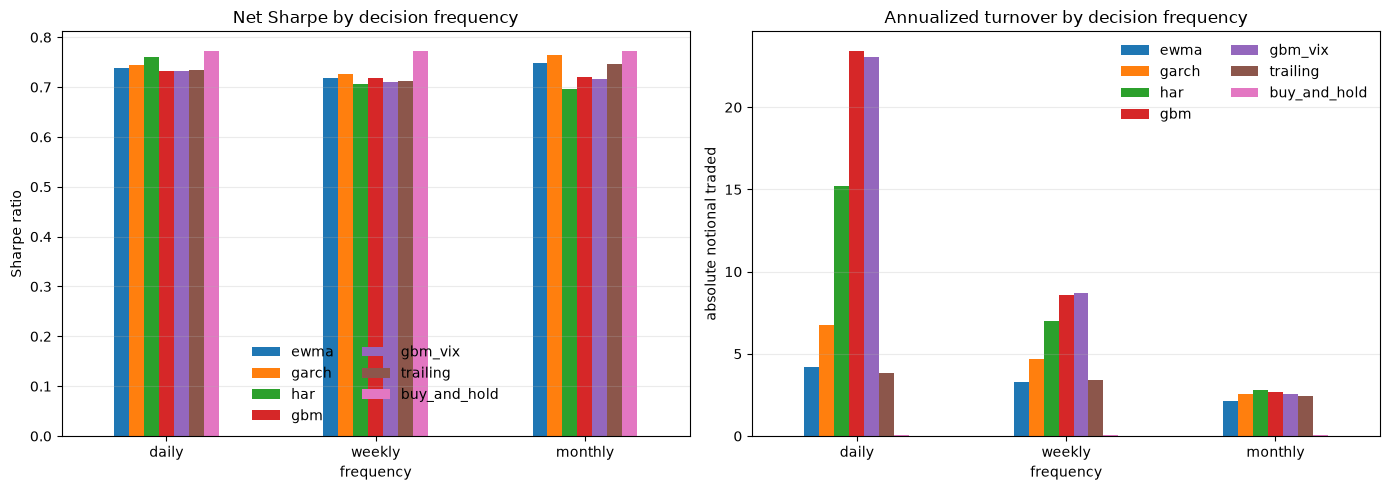

In [32]:
net_frequency = frequency_summary.xs("net", level="return_path")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
net_frequency["sharpe"].unstack("strategy").plot.bar(ax=axes[0])
net_frequency["annualized_turnover"].unstack("strategy").plot.bar(ax=axes[1])
axes[0].set_title("Net Sharpe by decision frequency")
axes[1].set_title("Annualized turnover by decision frequency")
axes[0].set_ylabel("Sharpe ratio")
axes[1].set_ylabel("absolute notional traded")
for ax in axes:
    ax.tick_params(axis="x", rotation=0)
    ax.legend(frameon=False, ncol=2)
    ax.grid(axis="y", alpha=0.25)
fig.tight_layout()
plt.show()

### Weekday sensitivity of weekly decisions

The weekly schedule above decides on the last trading day of each week. Anchoring the same schedule on each weekday, Monday to Friday, shows how much of the weekly result depends on the day chosen; when the anchor falls on a holiday the decision moves to the last trading day before it. The weight still executes at the next close, and the cap, band and costs are unchanged.

In [33]:
weekday_tables = {
    anchor: frequency_tables["weekly"] if anchor == base_config.weekly_anchor
    else run(
        config=replace(base_config, decision_frequency="weekly", weekly_anchor=anchor)
    )
    for anchor in WEEKDAYS
}
weekday_summary = pd.concat(
    {
        anchor: result["net_metrics"][[
            "sharpe", "maximum_drawdown", "annualized_turnover",
            "realized_volatility", "vol_of_vol",
        ]].assign(
            pvalue_vs_gbm=paired_pvalues(result["h3_sharpe"], "gbm"),
            pvalue_vs_passive=paired_pvalues(result["h3_sharpe"], BENCHMARK),
        )
        for anchor, result in weekday_tables.items()
    },
    names=["anchor"],
)
weekday_summary.round(4)

sharpe  maximum_drawdown  annualized_turnover  \
anchor strategy                                                      
MON    ewma          0.7227           -0.1388               3.3226   
       garch         0.7428           -0.1409               4.7261   
       har           0.7634           -0.1479               6.6762   
       gbm           0.7523           -0.1545               8.8722   
       gbm_vix       0.7579           -0.1621               8.5260   
       trailing      0.7402           -0.1595               3.4157   
       buy_and_hold  0.7732           -0.3372               0.0608   
TUE    ewma          0.7463           -0.1355               3.3503   
       garch         0.7688           -0.1450               4.6874   
       har           0.7988           -0.1453               6.7389   
       gbm           0.8031           -0.1577               8.3911   
       gbm_vix       0.7880           -0.1532               8.0816   
       trailing      0.7643           -0.1559               3.4567   
       buy_and_hold  0.7732           -0.3372               0.0608   
WED    ewma          0.7193           -0.1610               3.3852   
       garch         0.7113           -0.1527               4.7920   
       har           0.7465           -0.1707               6.7084   
       gbm           0.6800           -0.1828               8.4423   
       gbm_vix       0.6611           -0.1693               8.2843   
       trailing      0.7353           -0.1628               3.3438   
       buy_and_hold  0.7732           -0.3372               0.0608   
THU    ewma          0.7261           -0.1590               3.3091   
       garch         0.7437           -0.1460               4.5945   
       har           0.7661           -0.1598               6.6964   
       gbm           0.7934           -0.1659               8.2918   
       gbm_vix       0.7701           -0.1651               8.3747   
       trailing      0.7403           -0.1583               3.3626   
       buy_and_hold  0.7732           -0.3372               0.0608   
FRI    ewma          0.7181           -0.1555               3.3007   
       garch         0.7270           -0.1395               4.6558   
       har           0.7063           -0.1540               6.9727   
       gbm           0.7187           -0.1604               8.5637   
       gbm_vix       0.7098           -0.1685               8.6969   
       trailing      0.7119           -0.1577               3.4143   
       buy_and_hold  0.7732           -0.3372               0.0608   

                     realized_volatility  vol_of_vol  pvalue_vs_gbm  \
anchor strategy                                                       
MON    ewma                       0.1092      0.0376         0.5684   
       garch                      0.1034      0.0313         0.8232   
       har                        0.1028      0.0290         0.7443   
       gbm                        0.1057      0.0291            NaN   
       gbm_vix                    0.1035      0.0274         0.8282   
       trailing                   0.1110      0.0384         0.8012   
       buy_and_hold               0.1716      0.1022         0.8581   
TUE    ewma                       0.1101      0.0387         0.2458   
       garch                      0.1049      0.0330         0.4426   
       har                        0.1029      0.0302         0.8951   
       gbm                        0.1047      0.0293            NaN   
       gbm_vix                    0.1032      0.0284         0.5684   
       trailing                   0.1110      0.0388         0.3357   
       buy_and_hold               0.1716      0.1022         0.7862   
WED    ewma                       0.1112      0.0405         0.4685   
       garch                      0.1064      0.0354         0.5085   
       har                        0.1039      0.0317         0.0989   
       gbm                        0.1067      0.0321            NaN   
       gbm

## Gross and net earnings by frequency

Objective: compare how one unit of initial capital accumulates under each decision frequency before and after transaction costs. Cumulative earnings at date $t$ are $\prod_{s \leq t}(1+r_s)-1$; a value of 0.50 means that capital has earned 50% since the start of the out-of-sample period. The annual table keeps the last observed trading date of each year, including the partial final year.

In [34]:
frequency_returns = pd.concat(
    {
        frequency: pd.concat(
            {
                "gross": (cached := pd.read_parquet(
                    strategy_run_dir(
                        TRAIN_END,
                        replace(base_config, decision_frequency=frequency),
                    ) / "returns.parquet"
                )).xs("gross_return", axis=1, level=1),
                "net": cached.xs("net_return", axis=1, level=1),
            },
            axis=1,
            names=["return_path"],
        )
        for frequency in frequencies
    },
    axis=1,
    names=["frequency"],
)
frequency_earnings = (1.0 + frequency_returns).cumprod() - 1.0
annual_frequency_earnings = frequency_earnings.groupby(
    frequency_earnings.index.year
).tail(1)
annual_frequency_earnings.index.name = "date"
for frequency in frequencies:
    print(f"{frequency.title()} decisions")
    display(
        annual_frequency_earnings[frequency]
        .swaplevel(axis=1)
        .sort_index(axis=1)
        .round(4)
    )

Daily decisions


buy_and_hold            ewma           garch             gbm  \
return_path        gross     net   gross     net   gross     net   gross   
date                                                                       
2010-12-31        0.1314  0.1311  0.0975  0.0966  0.0988  0.0976  0.0764   
2011-12-30        0.1528  0.1526  0.1039  0.1023  0.1098  0.1077  0.0638   
2012-12-31        0.3372  0.3369  0.1935  0.1908  0.2078  0.2042  0.1475   
2013-12-31        0.7692  0.7688  0.4875  0.4827  0.4747  0.4685  0.4576   
2014-12-31        1.0074  1.0070  0.5942  0.5873  0.5737  0.5649  0.5232   
2015-12-31        1.0321  1.0317  0.5304  0.5225  0.5075  0.4975  0.4218   
2016-12-30        1.2759  1.2755  0.6069  0.5971  0.5837  0.5710  0.5221   
2017-12-29        1.7699  1.7694  1.0778  1.0628  0.9700  0.9509  0.9172   
2018-12-31        1.6434  1.6429  1.0251  1.0085  0.9251  0.9037  0.9150   
2019-12-31        2.4687  2.4681  1.3912  1.3696  1.2719  1.2432  1.3125   
2020-12-31        3.1046  3.1038  1.5191  1.4947  1.4744  1.4401  1.5548   
2021-12-31        4.2838  4.2828  1.9727  1.9411  1.8522  1.8075  2.0459   
2022-12-30        3.3235  3.3226  1.7090  1.6795  1.5897  1.5469  1.6739   
2023-12-29        4.4552  4.4541  2.1918  2.1552  2.0552  1.9994  2.1667   
2024-12-31        5.8128  5.8114  2.7703  2.7236  2.5600  2.4886  2.6843   
2025-12-31        7.0199  7.0183  3.0464  2.9932  2.8729  2.7893  3.0076   
2026-06-30        7.8293  7.8276  3.2492  3.1915  3.0563  2.9655  3.2548   

                    gbm_vix             har         trailing          
return_path     net   gross     net   gross     net    gross     net  
date                                                                  
2010-12-31   0.0726  0.0745  0.0713  0.0758  0.0737   0.0699  0.0693  
2011-12-30   0.0568  0.0586  0.0526  0.0697  0.0658   0.0649  0.0638  
2012-12-31   0.1353  0.1316  0.1206  0.1638  0.1572   0.1640  0.1621  
2013-12-31   0.4356  0.4438  0.4223  0.4516  0.4392   0.4906  0.4870  
2014-12-31   0.4915  0.5371  0.5047  0.5214  0.5039   0.5773  0.5719  
2015-12-31   0.3851  0.4305  0.3923  0.4327  0.4121   0.5004  0.4939  
2016-12-30   0.4747  0.5473  0.4973  0.5127  0.4863   0.5747  0.5665  
2017-12-29   0.8470  0.9417  0.8694  0.9195  0.8771   1.0431  1.0312  
2018-12-31   0.8360  0.9437  0.8617  0.9080  0.8597   1.0065  0.9927  
2019-12-31   1.2043  1.3254  1.2143  1.3124  1.2451   1.4104  1.3915  
2020-12-31   1.4259  1.5442  1.4152  1.5308  1.4512   1.5554  1.5334  
2021-12-31   1.8770  1.9631  1.7993  1.9908  1.8847   1.9947  1.9659  
2022-12-30   1.5189  1.6256  1.4743  1.6325  1.5351   1.6026  1.5764  
2023-12-29   1.9704  2.1154  1.9245  2.1256  2.0013   2.1269  2.0941  
2024-12-31   2.4364  2.6126  2.3716  2.6470  2.4876   2.7309  2.6886  
2025-12-31   2.7197  2.9505  2.6706  2.9833  2.7959   3.1018  3.0522  
2026-06-30   2.9378  3.1842  2.8783  3.2449  3.0378   3.3496  3.2955

Weekly decisions


buy_and_hold            ewma           garch             gbm  \
return_path        gross     net   gross     net   gross     net   gross   
date                                                                       
2010-12-31        0.1314  0.1311  0.1007  0.1000  0.1070  0.1061  0.1091   
2011-12-30        0.1528  0.1526  0.0962  0.0950  0.0957  0.0942  0.0952   
2012-12-31        0.3372  0.3369  0.1873  0.1853  0.1987  0.1962  0.2134   
2013-12-31        0.7692  0.7688  0.4777  0.4740  0.4602  0.4559  0.5427   
2014-12-31        1.0074  1.0070  0.5823  0.5768  0.5455  0.5393  0.6202   
2015-12-31        1.0321  1.0317  0.5286  0.5223  0.4920  0.4847  0.5397   
2016-12-30        1.2759  1.2755  0.6073  0.5994  0.5657  0.5566  0.6374   
2017-12-29        1.7699  1.7694  1.0844  1.0726  0.9621  0.9485  1.0994   
2018-12-31        1.6434  1.6429  1.0217  1.0086  0.9252  0.9098  0.9768   
2019-12-31        2.4687  2.4681  1.3757  1.3586  1.2664  1.2457  1.3043   
2020-12-31        3.1046  3.1038  1.4342  1.4153  1.3693  1.3454  1.3617   
2021-12-31        4.2838  4.2828  1.9039  1.8792  1.7933  1.7613  1.8539   
2022-12-30        3.3235  3.3226  1.6435  1.6204  1.5351  1.5052  1.5254   
2023-12-29        4.4552  4.4541  2.1183  2.0899  1.9998  1.9621  2.0127   
2024-12-31        5.8128  5.8114  2.7270  2.6902  2.5567  2.5078  2.5982   
2025-12-31        7.0199  7.0183  3.0057  2.9639  2.8450  2.7886  2.8749   
2026-06-30        7.8293  7.8276  3.2277  3.1821  3.0748  3.0130  3.1411   

                    gbm_vix             har         trailing          
return_path     net   gross     net   gross     net    gross     net  
date                                                                  
2010-12-31   0.1076  0.0952  0.0937  0.0948  0.0938   0.0882  0.0876  
2011-12-30   0.0925  0.0732  0.0705  0.0935  0.0914   0.0833  0.0822  
2012-12-31   0.2092  0.1867  0.1823  0.1990  0.1956   0.1852  0.1833  
2013-12-31   0.5349  0.5307  0.5223  0.5082  0.5014   0.5220  0.5186  
2014-12-31   0.6090  0.6282  0.6158  0.5860  0.5763   0.6211  0.6159  
2015-12-31   0.5261  0.4984  0.4838  0.5068  0.4955   0.5724  0.5661  
2016-12-30   0.6195  0.6038  0.5846  0.5637  0.5496   0.6376  0.6297  
2017-12-29   1.0728  1.0580  1.0293  0.9711  0.9498   1.1239  1.1126  
2018-12-31   0.9478  0.9459  0.9148  0.9005  0.8768   1.0309  1.0182  
2019-12-31   1.2656  1.2937  1.2524  1.2404  1.2092   1.3946  1.3775  
2020-12-31   1.3185  1.3477  1.3027  1.3450  1.3098   1.4865  1.4671  
2021-12-31   1.7955  1.7802  1.7214  1.8051  1.7575   1.9213  1.8959  
2022-12-30   1.4713  1.4516  1.3973  1.4386  1.3954   1.5530  1.5299  
2023-12-29   1.9444  1.9648  1.8957  1.8857  1.8315   2.0484  2.0196  
2024-12-31   2.5100  2.5536  2.4640  2.3838  2.3144   2.6229  2.5862  
2025-12-31   2.7712  2.8276  2.7232  2.6893  2.6078   3.0304  2.9867  
2026-06-30   3.0262  3.0944  2.9790  2.9518  2.8622   3.3151  3.2670

Monthly decisions


buy_and_hold            ewma           garch             gbm  \
return_path        gross     net   gross     net   gross     net   gross   
date                                                                       
2010-12-31        0.1314  0.1311  0.0779  0.0773  0.0898  0.0891  0.0489   
2011-12-30        0.1528  0.1526  0.0951  0.0942  0.1110  0.1100  0.0494   
2012-12-31        0.3372  0.3369  0.2041  0.2027  0.2347  0.2330  0.1418   
2013-12-31        0.7692  0.7688  0.5267  0.5243  0.5331  0.5303  0.4234   
2014-12-31        1.0074  1.0070  0.6545  0.6508  0.6482  0.6443  0.5321   
2015-12-31        1.0321  1.0317  0.5898  0.5857  0.5751  0.5705  0.4427   
2016-12-30        1.2759  1.2755  0.7436  0.7380  0.7222  0.7160  0.5470   
2017-12-29        1.7699  1.7694  1.2623  1.2544  1.1492  1.1405  0.9439   
2018-12-31        1.6434  1.6429  1.2214  1.2122  1.1223  1.1123  0.8945   
2019-12-31        2.4687  2.4681  1.6036  1.5912  1.4958  1.4822  1.2618   
2020-12-31        3.1046  3.1038  1.6316  1.6180  1.6289  1.6131  1.4585   
2021-12-31        4.2838  4.2828  2.1474  2.1298  2.0823  2.0619  1.8914   
2022-12-30        3.3235  3.3226  1.8876  1.8712  1.8370  1.8179  1.5512   
2023-12-29        4.4552  4.4541  2.4124  2.3923  2.3746  2.3509  2.0025   
2024-12-31        5.8128  5.8114  3.0988  3.0731  2.9518  2.9218  2.5215   
2025-12-31        7.0199  7.0183  3.6178  3.5870  3.5141  3.4772  3.0088   
2026-06-30        7.8293  7.8276  3.8477  3.8144  3.7135  3.6738  3.3282   

                    gbm_vix             har         trailing          
return_path     net   gross     net   gross     net    gross     net  
date                                                                  
2010-12-31   0.0483  0.0521  0.0516  0.0474  0.0469   0.0637  0.0632  
2011-12-30   0.0484  0.0565  0.0557  0.0591  0.0580   0.0856  0.0846  
2012-12-31   0.1402  0.1415  0.1402  0.1445  0.1430   0.1862  0.1847  
2013-12-31   0.4209  0.4368  0.4346  0.4496  0.4469   0.5207  0.5184  
2014-12-31   0.5285  0.5405  0.5371  0.5230  0.5191   0.6732  0.6698  
2015-12-31   0.4385  0.4463  0.4421  0.4244  0.4197   0.6100  0.6059  
2016-12-30   0.5416  0.5618  0.5566  0.5346  0.5286   0.7347  0.7292  
2017-12-29   0.9361  0.9671  0.9597  0.9271  0.9183   1.2402  1.2321  
2018-12-31   0.8858  0.9161  0.9079  0.8799  0.8701   1.1690  1.1598  
2019-12-31   1.2500  1.3161  1.3047  1.2441  1.2306   1.5304  1.5176  
2020-12-31   1.4443  1.5083  1.4948  1.3993  1.3836   1.5656  1.5512  
2021-12-31   1.8719  1.8652  1.8474  1.7970  1.7765   2.0724  2.0534  
2022-12-30   1.5329  1.5079  1.4910  1.4484  1.4295   1.7664  1.7486  
2023-12-29   1.9797  1.9478  1.9265  1.9295  1.9063   2.2862  2.2640  
2024-12-31   2.4933  2.4820  2.4550  2.4327  2.4042   3.0070  2.9784  
2025-12-31   2.9749  2.9516  2.9193  2.9336  2.8993   3.5684  3.5337  
2026-06-30   3.2908  3.2455  3.2100  3.1729  3.1348   3.8295  3.7914

In [35]:
ending_frequency_earnings = frequency_earnings.iloc[-1].unstack(
    ["frequency", "return_path"]
)
ending_frequency_earnings.round(4)

frequency      daily          weekly         monthly        
return_path    gross     net   gross     net   gross     net
ewma          3.2492  3.1915  3.2277  3.1821  3.8477  3.8144
garch         3.0563  2.9655  3.0748  3.0130  3.7135  3.6738
har           3.2449  3.0378  2.9518  2.8622  3.1729  3.1348
gbm           3.2548  2.9378  3.1411  3.0262  3.3282  3.2908
gbm_vix       3.1842  2.8783  3.0944  2.9790  3.2455  3.2100
trailing      3.3496  3.2955  3.3151  3.2670  3.8295  3.7914
buy_and_hold  7.8293  7.8276  7.8293  7.8276  7.8293  7.8276

### Gross and net earnings paths

These panels plot the complete cumulative-earnings time series behind the tables. Rows change only the decision frequency; columns separate the cost-free and cost-aware portfolio paths. All panels share the same vertical scale, so lower turnover can be compared without hiding changes in cumulative performance.

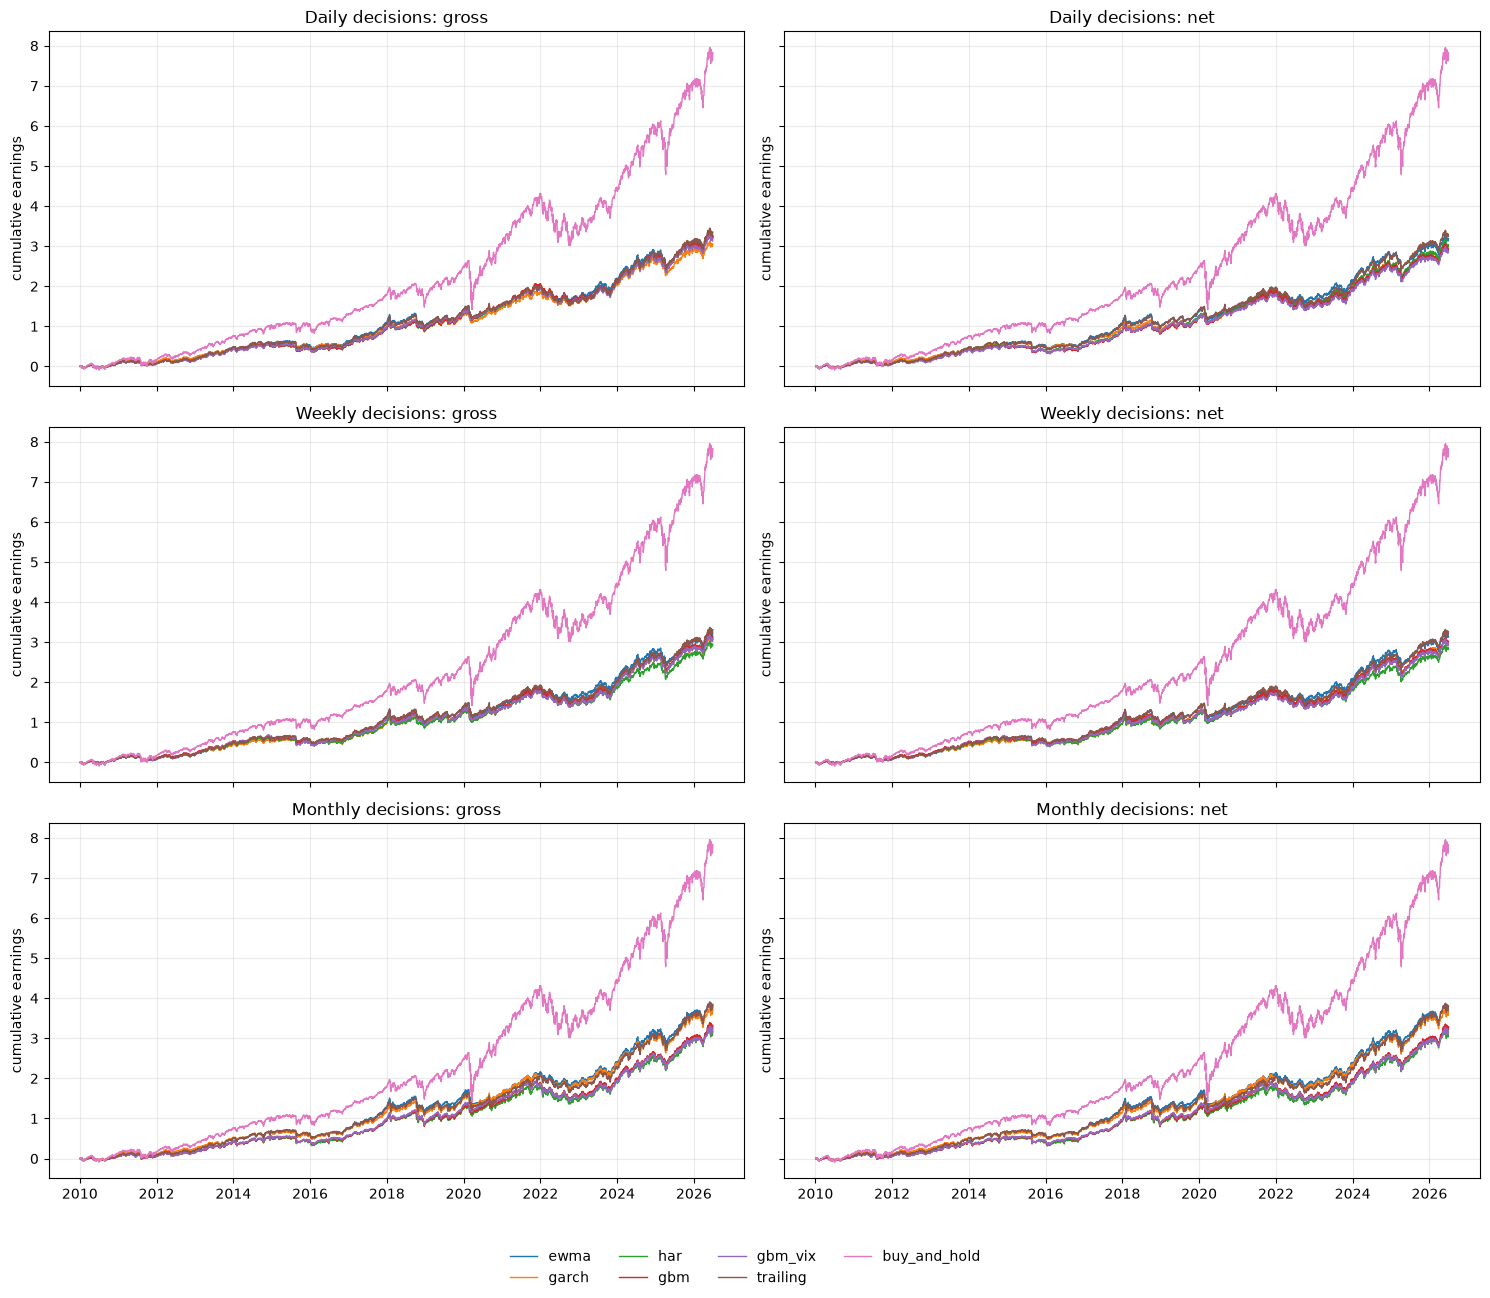

In [36]:
fig, axes = plt.subplots(3, 2, figsize=(15, 13), sharex=True, sharey=True)
for row, frequency in enumerate(frequencies):
    for column, return_path in enumerate(("gross", "net")):
        ax = axes[row, column]
        panel = frequency_earnings[frequency, return_path]
        for strategy in panel:
            ax.plot(panel.index, panel[strategy], lw=1.0, label=strategy)
        ax.set_title(f"{frequency.title()} decisions: {return_path}")
        ax.set_ylabel("cumulative earnings")
        ax.grid(alpha=0.25)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
fig.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()